 Autoencoder — Rekonstruksi dan Kompresi Gambar (dataset MNIST)**

Nama: Muhammad Aldi Almi  |  NIM: 2411002  |
Nama: Esnang Anargya Wicaksana |  NIM: 2411010  |  
MK Metode Kecerdasan Buatan

# BAGIAN A — Pertanyaan Teori

### Jawaban A1: Transfer Learning

**Siapa yang lebih benar?** Budi lebih benar, terutama kalau datanya sedikit. Pernyataan Ani keliru karena model *pretrained* tidak perlu dilatih dari nol. Layer-layer awal ResNet sudah belajar fitur umum seperti tepi, sudut, tekstur, dan bentuk dari jutaan gambar ImageNet, dan fitur ini bisa dipakai ulang di dataset baru.

**Nama teknik.** Teknik Budi disebut **feature extraction**: semua layer *pretrained* di-*freeze* (*freezing layer*, `trainable = False`) sebagai pengekstrak fitur, lalu hanya layer klasifikasi baru di bagian akhir yang dilatih. Teknik yang dimaksud Ani paling dekat dengan **finetuning**, yaitu membuka (*unfreeze*) sebagian atau seluruh layer *pretrained* dan melatihnya lagi dengan learning rate kecil. Bedanya, finetuning yang benar tetap memulai dari bobot *pretrained*, bukan dari bobot acak. Kalau bobotnya benar-benar diacak ulang, itu namanya *training from scratch*.

**Kapan dipakai.** Cara Budi (feature extraction) cocok saat data kita sedikit dan mirip dengan ImageNet, misalnya 5 jenis buah. Training-nya cepat dan risiko *overfitting* kecil karena hanya sedikit parameter yang dilatih. Cara Ani (finetuning) cocok saat data banyak atau domainnya berbeda jauh dari ImageNet, misalnya citra medis atau satelit, karena fitur bawaan perlu disesuaikan dan data yang banyak cukup untuk melatih ulang layer-layer itu tanpa *overfitting*.

### Jawaban A2: RNN dan LSTM

**Apakah ini data sekuensial?** Ya. Data sekuensial adalah data yang **urutannya bermakna**, artinya nilai pada waktu tertentu bergantung pada nilai-nilai sebelumnya. Suhu hari ini berkaitan dengan suhu kemarin dan tren beberapa hari terakhir. Kalau urutan 30 hari itu diacak, polanya hilang, jadi modelnya harus memperhatikan urutan.

**Mengapa LSTM lebih cocok daripada RNN vanilla?** RNN vanilla mengalami *vanishing gradient*. Saat *backpropagation through time* melewati 30 langkah, gradien dikalikan berulang-ulang sampai mengecil mendekati nol. Akibatnya informasi dari hari-hari awal (misalnya hari ke-1 sampai ke-10) hampir tidak memengaruhi bobot, sehingga RNN seperti punya ingatan jangka pendek saja. LSTM mengatasinya dengan *cell state*, yaitu jalur memori yang diperbarui secara aditif dan dikontrol oleh gate (forget, input, output), sehingga gradien bisa mengalir jauh ke belakang. Analoginya, RNN vanilla seperti ingatan manusia yang cepat lupa, sedangkan LSTM seperti punya buku catatan yang bisa dipilih mana yang dicatat, dipertahankan, atau dihapus.

**Beda mendasar LSTM dan GRU.** LSTM punya 3 gate (forget, input, output) dan *cell state* terpisah dari *hidden state*. GRU lebih ringkas: hanya 2 gate (update dan reset) dan tanpa *cell state* terpisah, sehingga parameternya lebih sedikit dan training lebih cepat.

### Jawaban A3: Autoencoder

**Vektor 32 angka.** Vektor ini disebut **bottleneck**, yaitu representasi di **latent space**. Fungsinya memaksa model memampatkan gambar 784 piksel menjadi 32 angka (kompresi sekitar 24,5 kali), sehingga encoder hanya bisa menyimpan ciri-ciri paling penting (bentuk garis, lengkungan, dst.) dan decoder harus merekonstruksi gambar dari ringkasan itu saja.

**Tanpa label.** Autoencoder bersifat **unsupervised** (lebih tepatnya *self-supervised*) karena targetnya adalah **inputnya sendiri**: `fit(X, X)`. Loss dihitung dari selisih gambar asli dan gambar hasil rekonstruksi (*reconstruction error*), bukan dari kecocokan dengan label manusia. Model klasifikasi kucing/anjing berbeda karena butuh label `y` untuk setiap gambar, dan loss-nya membandingkan prediksi kelas dengan label itu.

**Gambar yang belum pernah dilihat.** Kalau gambar itu berasal dari jenis yang sama dengan data latih (angka tulisan tangan baru), rekonstruksinya tetap bagus. Kalau gambar itu jauh berbeda dari data latih (misalnya foto baju, huruf, atau noise), rekonstruksinya akan buruk, buram, atau malah menyerupai angka karena model hanya hafal pola data yang pernah dilihat. Akibatnya **reconstruction error-nya tinggi**. Inilah prinsip **deteksi anomali**: latih autoencoder hanya pada data normal, lalu tetapkan ambang (*threshold*) error. Data dengan error di atas ambang dianggap tidak normal (anomali).

# BAGIAN B — Implementasi: Opsi 3 Autoencoder

In [ ]:
# Import semua library yang dibutuhkan
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from sklearn.decomposition import PCA
from IPython.display import Markdown, display

# Kunci seed supaya hasil bisa direproduksi
np.random.seed(42)
tf.random.set_seed(42)

## Langkah 1: Persiapan Data

In [ ]:
# Load MNIST langsung dari Keras; label diabaikan (_) karena autoencoder tidak butuh label
(X_train, _), (X_test, _) = mnist.load_data()
print("Shape awal   :", X_train.shape, X_test.shape)

# Normalisasi piksel dari [0, 255] menjadi [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Flatten: ubah tiap gambar (28, 28) menjadi vektor (784,)
X_train = X_train.reshape(len(X_train), 784)
X_test = X_test.reshape(len(X_test), 784)

# Tampilkan shape setelah preprocessing
print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape awal   : (60000, 28, 28) (10000, 28, 28)
Shape X_train: (60000, 784)
Shape X_test : (10000, 784)


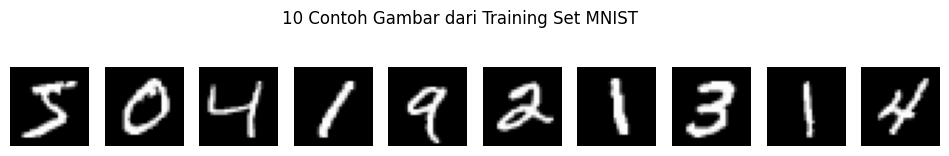

In [ ]:
# Tampilkan 10 contoh gambar dari training set sebagai gambar (bukan angka)
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")  # kembalikan ke 28x28 hanya untuk ditampilkan
    plt.axis("off")
plt.suptitle("10 Contoh Gambar dari Training Set MNIST")
plt.show()

## Langkah 2: Model Baseline — PCA (32 komponen)

In [ ]:
# Fit PCA pada data latih, lalu kompres dan rekonstruksi data test
pca = PCA(n_components=32)
X_train_pca = pca.fit_transform(X_train)
X_test_reconstructed_pca = pca.inverse_transform(pca.transform(X_test))

# Hitung MSE antara X_test asli dan hasil rekonstruksi PCA
mse_pca = np.mean((X_test - X_test_reconstructed_pca) ** 2)
print(f"MSE rekonstruksi PCA: {mse_pca:.6f}")
print(f"Total varians yang dipertahankan 32 komponen: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

MSE rekonstruksi PCA: 0.016828
Total varians yang dipertahankan 32 komponen: 74.36%


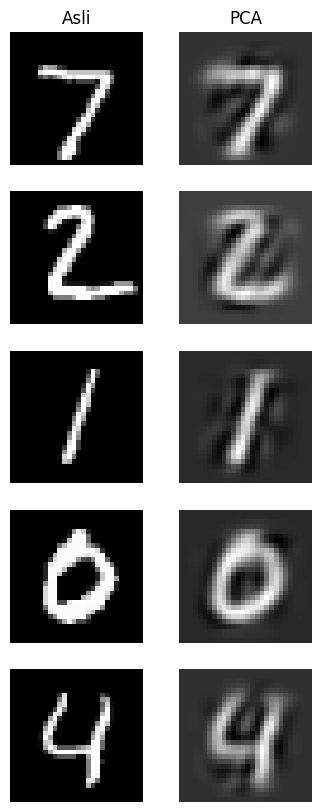

In [ ]:
# Tampilkan 5 gambar: kolom kiri = asli, kolom kanan = rekonstruksi PCA
plt.figure(figsize=(4, 10))
for i in range(5):
    plt.subplot(5, 2, 2 * i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0: plt.title("Asli")
    plt.subplot(5, 2, 2 * i + 2)
    plt.imshow(X_test_reconstructed_pca[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == 0: plt.title("PCA")
plt.show()

## Langkah 3: Model Autoencoder

In [ ]:
# ENCODER: 784 -> 128 -> 32 (bottleneck)
input_layer = Input(shape=(784,))
encoded = Dense(128, activation="relu")(input_layer)
encoded = Dense(32, activation="relu")(encoded)  # bottleneck (32 dimensi)

# DECODER: 32 -> 128 -> 784 (sigmoid agar output berada di rentang [0, 1] sama seperti input)
decoded = Dense(128, activation="relu")(encoded)
output_layer = Dense(784, activation="sigmoid")(decoded)

# Gabungkan jadi satu model dan compile (loss MSE = selisih piksel asli vs rekonstruksi)
autoencoder = Model(input_layer, output_layer)
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Latih model: X_train sebagai INPUT sekaligus TARGET (bukan label!)
history = autoencoder.fit(
    X_train, X_train,
    epochs=30,
    batch_size=256,
    validation_data=(X_test, X_test),
    verbose=2
)

Epoch 1/30
235/235 - 7s - 29ms/step - loss: 0.0580 - val_loss: 0.0311
Epoch 2/30
235/235 - 8s - 33ms/step - loss: 0.0252 - val_loss: 0.0203
Epoch 3/30
235/235 - 3s - 13ms/step - loss: 0.0187 - val_loss: 0.0166
Epoch 4/30
235/235 - 4s - 19ms/step - loss: 0.0160 - val_loss: 0.0146
Epoch 5/30
235/235 - 3s - 12ms/step - loss: 0.0144 - val_loss: 0.0135
Epoch 6/30
235/235 - 5s - 22ms/step - loss: 0.0134 - val_loss: 0.0127
Epoch 7/30
235/235 - 4s - 19ms/step - loss: 0.0126 - val_loss: 0.0120
Epoch 8/30
235/235 - 3s - 12ms/step - loss: 0.0122 - val_loss: 0.0116
Epoch 9/30
235/235 - 3s - 12ms/step - loss: 0.0118 - val_loss: 0.0113
Epoch 10/30
235/235 - 3s - 12ms/step - loss: 0.0115 - val_loss: 0.0111
Epoch 11/30
235/235 - 4s - 16ms/step - loss: 0.0113 - val_loss: 0.0109
Epoch 12/30
235/235 - 5s - 21ms/step - loss: 0.0111 - val_loss: 0.0107
Epoch 13/30
235/235 - 3s - 12ms/step - loss: 0.0109 - val_loss: 0.0105
Epoch 14/30
235/235 - 3s - 12ms/step - loss: 0.0107 - val_loss: 0.0103
Epoch 15/30
235

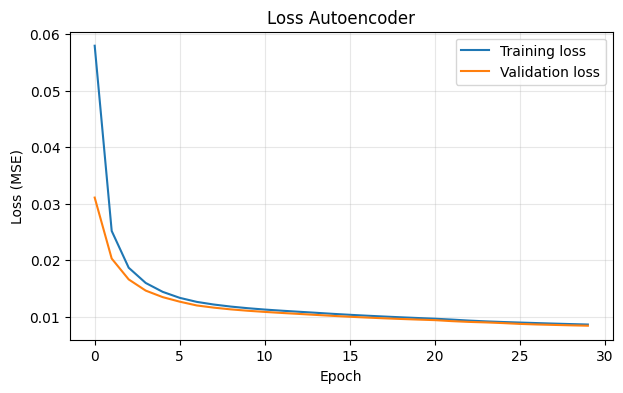

In [ ]:
# Plot loss training dan validation selama 30 epoch
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.title("Loss Autoencoder")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Rekonstruksi X_test dengan autoencoder, lalu hitung MSE-nya
X_reconstructed = autoencoder.predict(X_test)
mse_ae = np.mean((X_test - X_reconstructed) ** 2)
print(f"MSE rekonstruksi Autoencoder: {mse_ae:.6f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
MSE rekonstruksi Autoencoder: 0.008426


## Langkah 4: Bandingkan dan Visualisasi

In [ ]:
# Tabel perbandingan (ditampilkan sebagai Markdown dengan angka hasil run sendiri)
tabel = f'''
| Metode | Dimensi Asli | Dimensi Kompresi | MSE Rekonstruksi |
|---|---|---|---|
| PCA | 784 | 32 | {mse_pca:.6f} |
| Autoencoder | 784 | 32 | {mse_ae:.6f} |
'''
display(Markdown(tabel))


| Metode | Dimensi Asli | Dimensi Kompresi | MSE Rekonstruksi |
|---|---|---|---|
| PCA | 784 | 32 | 0.016828 |
| Autoencoder | 784 | 32 | 0.008426 |


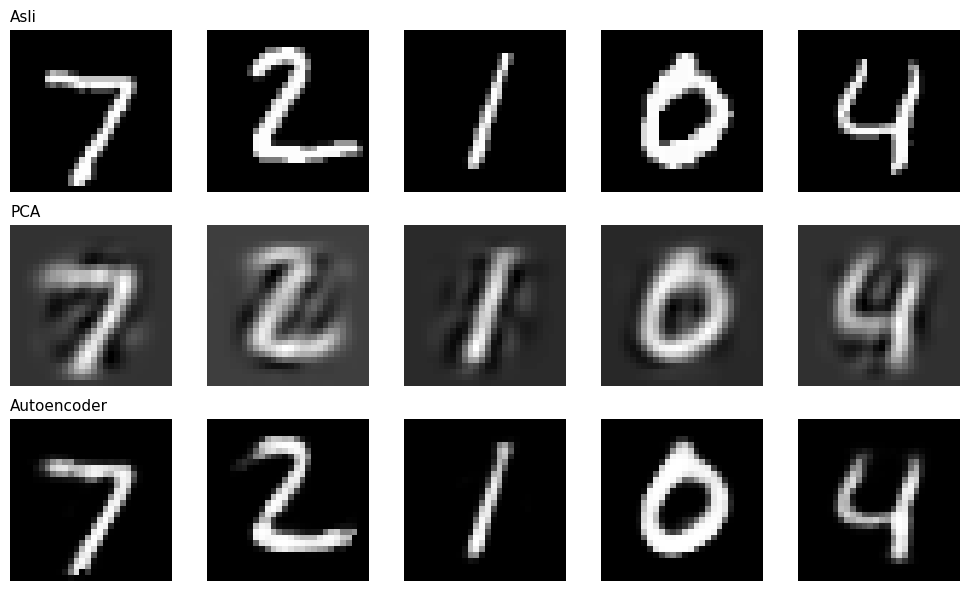

In [ ]:
# Bandingkan visual 5 gambar test yang sama: baris 1 asli, baris 2 PCA, baris 3 Autoencoder
n = 5
baris = [("Asli", X_test), ("PCA", X_test_reconstructed_pca), ("Autoencoder", X_reconstructed)]
plt.figure(figsize=(10, 6))
for r, (nama, data) in enumerate(baris):
    for i in range(n):
        plt.subplot(3, n, r * n + i + 1)
        plt.imshow(data[i].reshape(28, 28), cmap="gray")
        plt.axis("off")
        if i == 0:
            plt.title(nama, loc="left", fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# Ringkasan otomatis dari angka hasil run (gunakan sebagai bahan, lalu tulis ulang dengan kata-katamu sendiri)
selisih = abs(mse_pca - mse_ae) / mse_pca * 100
lebih_baik = "Autoencoder" if mse_ae < mse_pca else "PCA"
print(f"MSE PCA = {mse_pca:.6f} | MSE Autoencoder = {mse_ae:.6f}")
print(f"Secara angka, {lebih_baik} lebih baik dengan selisih sekitar {selisih:.1f}%.")

MSE PCA = 0.016828 | MSE Autoencoder = 0.008426
Secara angka, Autoencoder lebih baik dengan selisih sekitar 49.9%.


### Analisis Perbandingan (3–5 kalimat)

*Isi setelah notebook dijalankan, berdasarkan angka MSE dan gambar yang muncul di notebook-mu. Poin yang perlu dijawab:*

1. Rekonstruksi mana yang lebih bagus secara visual (PCA atau Autoencoder)? Lihat ketajaman garis dan apakah bentuk angka masih jelas.
2. Apakah angka MSE sesuai dengan apa yang terlihat? (Catatan: MSE rata-rata di seluruh piksel, dan latar yang hitam mendominasi gambar, jadi selisih kecil di MSE bisa terlihat lebih jelas secara visual.)
3. Kelebihan Autoencoder selain MSE: bersifat **non-linear** (PCA hanya linear), sehingga bisa menangkap pola yang lebih kompleks. Arsitekturnya bisa dikembangkan (convolutional, denoising, variational), dan error rekonstruksinya bisa dipakai untuk **deteksi anomali**. Kekurangannya, perlu training dan tuning, sedangkan PCA langsung dihitung secara analitik.

In [ ]:
# (Opsional) Demo deteksi anomali untuk mendukung jawaban A3:
# bandingkan reconstruction error gambar digit asli vs gambar noise acak yang tidak pernah dilihat model
digit = X_test[:1000]
noise = np.random.rand(1000, 784).astype("float32")

err_digit = np.mean((digit - autoencoder.predict(digit, verbose=0)) ** 2, axis=1)
err_noise = np.mean((noise - autoencoder.predict(noise, verbose=0)) ** 2, axis=1)

print(f"Rata-rata reconstruction error digit asli : {err_digit.mean():.6f}")
print(f"Rata-rata reconstruction error noise acak : {err_noise.mean():.6f}")

Rata-rata reconstruction error digit asli : 0.008782
Rata-rata reconstruction error noise acak : 0.286763


BAGIAN C — REFLEKSI
C1 — Apa yang Kamu Pelajari?
Hal yang paling saya pahami dari materi pertemuan 1–7 adalah cara kerja Autoencoder untuk mengompresi dan merekonstruksi gambar. Contohnya pada dataset MNIST, gambar berukuran 784 dimensi dikompresi menjadi 32 dimensi, kemudian direkonstruksi kembali. Hal yang masih membingungkan bagi saya adalah memahami proses kerja setiap layer pada neural network. Menurut saya, AI sangat berguna dalam kehidupan sehari-hari, contohnya teknologi pengenalan wajah pada smartphone yang dapat mengenali pemiliknya secara otomatis.
C2 — Proses Pengerjaanmu
1. Bagian paling sulit dan cara menyelesaikannya
Bagian paling sulit adalah memahami pembuatan model Autoencoder dan membandingkan hasilnya dengan PCA. Saya mengatasinya dengan mempelajari fungsi setiap bagian kode dan menjalankannya secara bertahap.
2. Total waktu pengerjaan
Saya menghabiskan waktu sekitar 6 jam, dengan pembagian:
Bagian A (Teori): 2 jam.
Bagian B (Preprocessing): 1 jam.
Pembuatan dan training model: 2 jam.
Evaluasi dan analisis hasil: 1 jam.
3. Fitur atau eksperimen tambahan
Saya ingin mencoba menambahkan gambar yang memiliki noise untuk mengetahui apakah Autoencoder mampu memperbaiki dan merekonstruksi gambar tersebut menjadi lebih jelas.
Catatan: Sesuaikan waktu pengerjaan dengan waktu sebenarnya. Jawaban lainnya sudah disesuaikan dengan proyek Autoencoder yang kamu kerjakan.